Walmart Weekly Sales Prediction

End-to-End Machine Learning Project

Objective

The objective of this project is to predict Walmart's weekly sales using historical sales, store, date, holiday, temperature, fuel price, CPI, and unemployment data.

Problem Type

This is a Regression problem because the target variable, Weekly_Sales, is a continuous numerical value.

1. Problem Statement

Walmart's weekly sales are influenced by several factors such as store, date, holidays, temperature, fuel price, consumer price index (CPI), and unemployment.

The aim of this project is to develop machine learning regression models that can learn from historical Walmart data and predict weekly sales for new and unseen data.


In [28]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

2. Dataset Loading

The Walmart dataset is loaded using Pandas. The dataset contains historical weekly sales records along with store, date, holiday, temperature, fuel price, CPI, and unemployment information.

The dataset is loaded first so that its structure and contents can be examined before performing data preprocessing and machine learning.

In [ ]:
from pathlib import Path

candidate_paths = [
    Path("../data/raw/Walmart.csv"),
    Path("data/raw/Walmart.csv"),
    Path("Walmart.csv"),
]
data_path = next((path for path in candidate_paths if path.exists()), None)
if data_path is None:
    raise FileNotFoundError("Walmart.csv was not found in the project data folders.")

df = pd.read_csv(data_path)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

df.head()

Dataset loaded successfully!
Dataset shape: (6435, 8)


,Store,Date,Weekly_Sales,Holiday_Flag,Temperature,Fuel_Price,CPI,Unemployment
0,1,05-02-2010,1643690.90,0,42.31,2.572,211.096358,8.106
1,1,12-02-2010,1641957.44,1,38.51,2.548,211.242170,8.106
2,1,19-02-2010,1611968.17,0,39.93,2.514,211.289143,8.106
3,1,26-02-2010,1409727.59,0,46.63,2.561,211.319643,8.106
4,1,05-03-2010,1554806.68,0,46.50,2.625,211.350143,8.106


3. Dataset Understanding

Before preprocessing the data, we inspect the dataset structure, column names, data types, statistical summary, and the number of records.

This helps us understand the nature of each feature and identify the target variable for the regression problem.

In [30]:
print("Dataset Information:")
df.info()

print("\nColumn Names:")
print(df.columns.tolist())

print("\nStatistical Summary:")
print(df.describe())

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6435 entries, 0 to 6434
Data columns (total 8 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Store         6435 non-null   int64  
 1   Date          6435 non-null   object 
 2   Weekly_Sales  6435 non-null   float64
 3   Holiday_Flag  6435 non-null   int64  
 4   Temperature   6435 non-null   float64
 5   Fuel_Price    6435 non-null   float64
 6   CPI           6435 non-null   float64
 7   Unemployment  6435 non-null   float64
dtypes: float64(5), int64(2), object(1)
memory usage: 402.3+ KB

Column Names:
['Store', 'Date', 'Weekly_Sales', 'Holiday_Flag', 'Temperature', 'Fuel_Price', 'CPI', 'Unemployment']

Statistical Summary:
             Store  Weekly_Sales  Holiday_Flag  Temperature   Fuel_Price  \
count  6435.000000  6.435000e+03   6435.000000  6435.000000  6435.000000   
mean     23.000000  1.046965e+06      0.069930    60.663782     3.358607   
std      12.

4. Data Quality Check

Data quality is checked by identifying missing values and duplicate records.

Missing values can affect model training, while duplicate records can introduce repeated information and bias the analysis. Therefore, both are checked before further processing.

In [31]:
print("Missing Values:")
print(df.isnull().sum())

print("\nNumber of Duplicate Rows:")
print(df.duplicated().sum())

Missing Values:
Store           0
Date            0
Weekly_Sales    0
Holiday_Flag    0
Temperature     0
Fuel_Price      0
CPI             0
Unemployment    0
dtype: int64

Number of Duplicate Rows:
0


5. Exploratory Data Analysis

Exploratory Data Analysis is performed to understand the distribution of weekly sales and identify important patterns and relationships in the dataset.

Different visualizations are used to study sales distribution, store-wise sales, sales trends over time, holiday effects, and correlations among numerical variables.

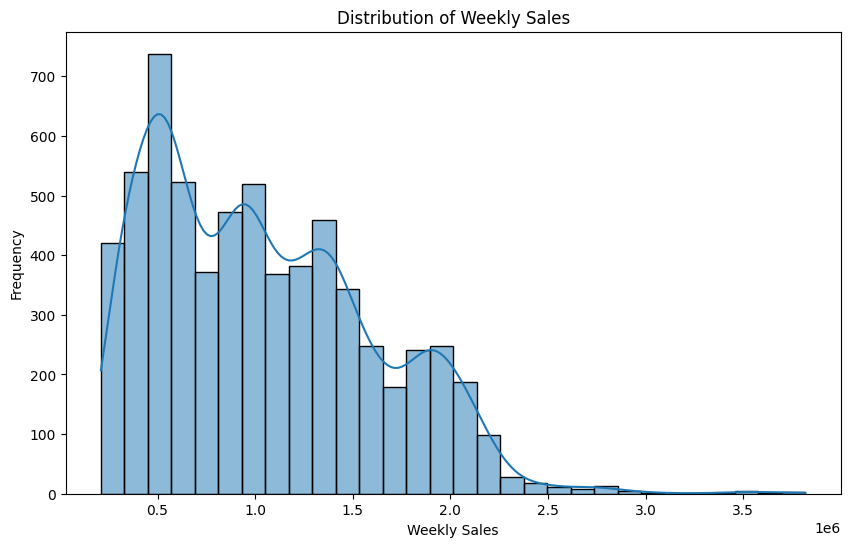

In [32]:
plt.figure(figsize=(10, 6))
sns.histplot(df["Weekly_Sales"], bins=30, kde=True)
plt.title("Distribution of Weekly Sales")
plt.xlabel("Weekly Sales")
plt.ylabel("Frequency")
plt.show()

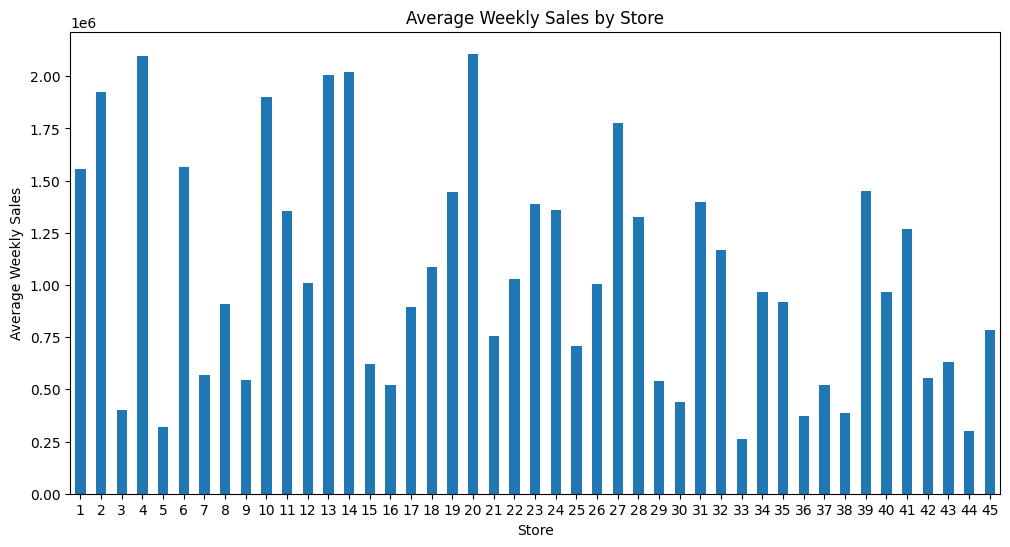

In [33]:
store_sales = df.groupby("Store")["Weekly_Sales"].mean()

plt.figure(figsize=(12, 6))
store_sales.plot(kind="bar")
plt.title("Average Weekly Sales by Store")
plt.xlabel("Store")
plt.ylabel("Average Weekly Sales")
plt.xticks(rotation=0)
plt.show()

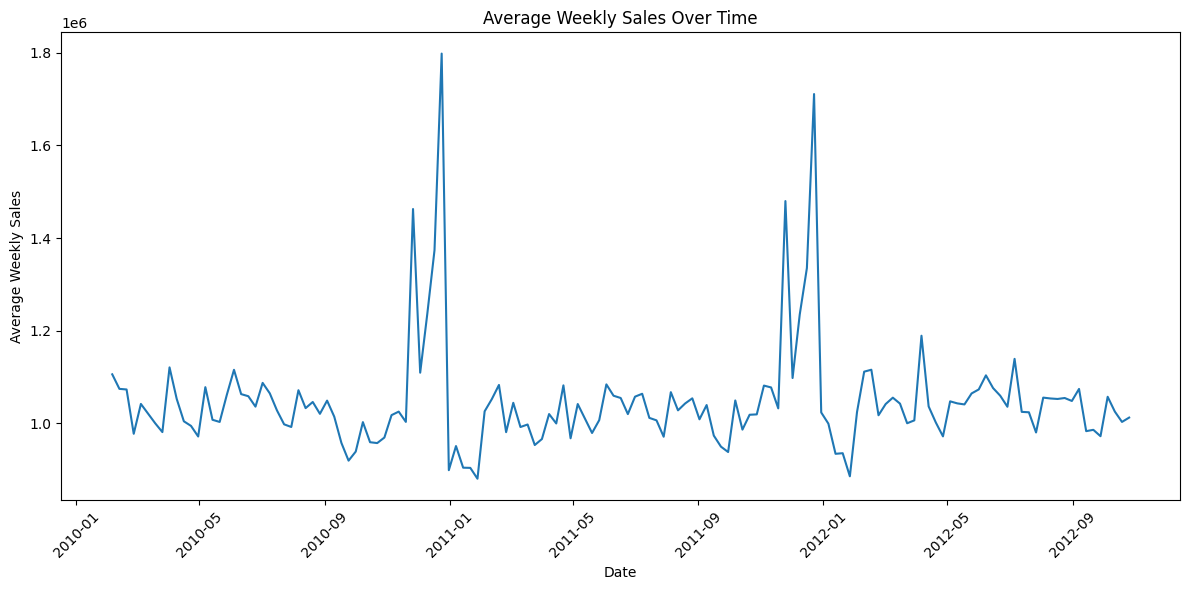

In [34]:
df["Date"] = pd.to_datetime(df["Date"], dayfirst=True)

daily_sales = df.groupby("Date")["Weekly_Sales"].mean()

plt.figure(figsize=(12, 6))
plt.plot(daily_sales)
plt.title("Average Weekly Sales Over Time")
plt.xlabel("Date")
plt.ylabel("Average Weekly Sales")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

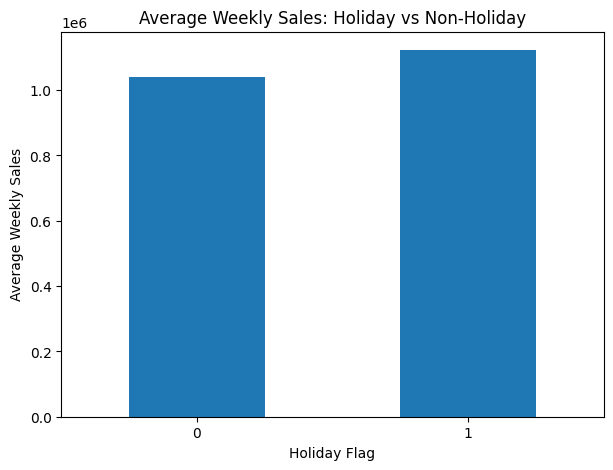

In [35]:
holiday_sales = df.groupby("Holiday_Flag")["Weekly_Sales"].mean()

plt.figure(figsize=(7, 5))
holiday_sales.plot(kind="bar")
plt.title("Average Weekly Sales: Holiday vs Non-Holiday")
plt.xlabel("Holiday Flag")
plt.ylabel("Average Weekly Sales")
plt.xticks(rotation=0)
plt.show()

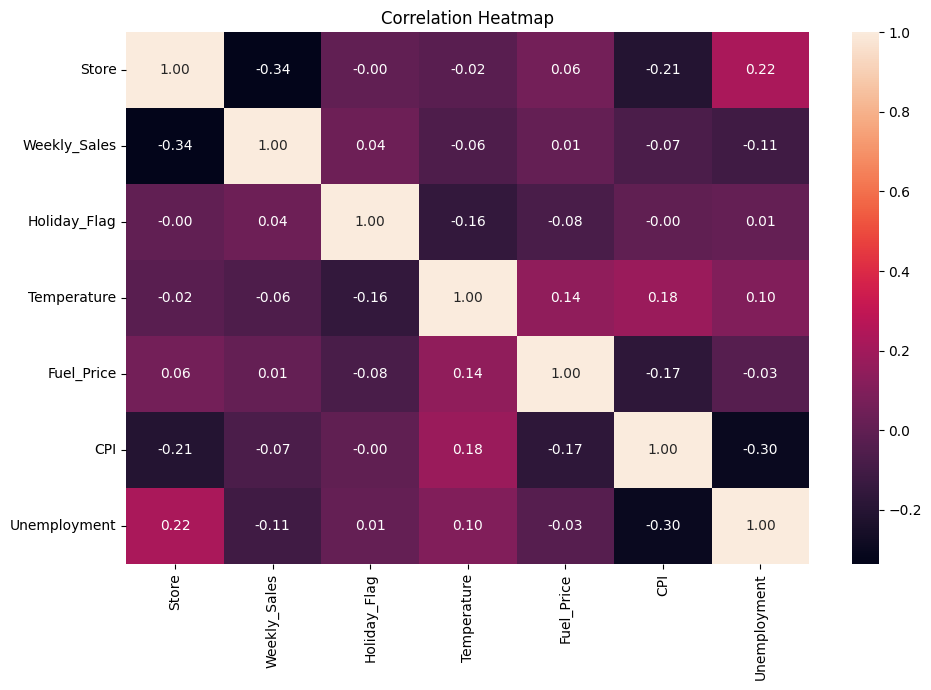

In [36]:
plt.figure(figsize=(10, 7))

correlation = df.select_dtypes(include=np.number).corr()

sns.heatmap(correlation, annot=True, fmt=".2f")
plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()

6. Data Preprocessing

The Date column is converted into a datetime format so that useful time-based features can be extracted.

The dataset is also checked for missing and duplicate values. Since the earlier data quality check showed no missing values and no duplicate records, no rows need to be removed or imputed at this stage.

In [37]:
df["Date"] = pd.to_datetime(df["Date"], dayfirst=True)

print("Date column converted successfully.")
print(df.dtypes)

Date column converted successfully.
Store                    int64
Date            datetime64[ns]
Weekly_Sales           float64
Holiday_Flag             int64
Temperature            float64
Fuel_Price             float64
CPI                    float64
Unemployment           float64
dtype: object


7. Feature Engineering

The original Date column contains useful information about the time period of each sales record.

To help the regression models learn seasonal and time-related patterns, Year, Month, Week, and Day features are extracted from the Date column.

In [38]:
df["Year"] = df["Date"].dt.year
df["Month"] = df["Date"].dt.month
df["Week"] = df["Date"].dt.isocalendar().week.astype(int)
df["Day"] = df["Date"].dt.day

print("New features created successfully.")
print(df.head())

New features created successfully.
   Store       Date  Weekly_Sales  Holiday_Flag  Temperature  Fuel_Price  \
0      1 2010-02-05    1643690.90             0        42.31       2.572   
1      1 2010-02-12    1641957.44             1        38.51       2.548   
2      1 2010-02-19    1611968.17             0        39.93       2.514   
3      1 2010-02-26    1409727.59             0        46.63       2.561   
4      1 2010-03-05    1554806.68             0        46.50       2.625   

          CPI  Unemployment  Year  Month  Week  Day  
0  211.096358         8.106  2010      2     5    5  
1  211.242170         8.106  2010      2     6   12  
2  211.289143         8.106  2010      2     7   19  
3  211.319643         8.106  2010      2     8   26  
4  211.350143         8.106  2010      3     9    5  


In [39]:
df = df.drop("Date", axis=1)

print("Date column removed after extracting useful time-based features.")
print(df.columns.tolist())

Date column removed after extracting useful time-based features.
['Store', 'Weekly_Sales', 'Holiday_Flag', 'Temperature', 'Fuel_Price', 'CPI', 'Unemployment', 'Year', 'Month', 'Week', 'Day']


8. Feature and Target Selection

Weekly_Sales is selected as the target variable because it is the value we want to predict.

All remaining relevant numerical columns are used as input features for the regression models.

In [40]:
X = df.drop("Weekly_Sales", axis=1)
y = df["Weekly_Sales"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (6435, 10)
Target shape: (6435,)


9. Train-Test Split

The dataset is divided into training and testing sets.

The training data is used to teach the machine learning models, while the testing data is used to evaluate how well the trained models perform on unseen data.

80% of the data is used for training and 20% for testing.

In [41]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (5148, 10)
Testing data: (1287, 10)


10. Linear Regression

Linear Regression is used as a baseline regression model. It assumes a linear relationship between the input features and Weekly_Sales.

The model is trained using the training data and evaluated on the unseen test data using MAE, MSE, RMSE, and R² score.

In [42]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

linear_model = LinearRegression()

linear_model.fit(X_train, y_train)

linear_predictions = linear_model.predict(X_test)

linear_mae = mean_absolute_error(y_test, linear_predictions)
linear_mse = mean_squared_error(y_test, linear_predictions)
linear_rmse = np.sqrt(linear_mse)
linear_r2 = r2_score(y_test, linear_predictions)

print("Linear Regression Results")
print("MAE :", linear_mae)
print("MSE :", linear_mse)
print("RMSE:", linear_rmse)
print("R²  :", linear_r2)

Linear Regression Results
MAE : 432598.0289778756
MSE : 272062452501.9959
RMSE: 521596.06258291093
R²  : 0.15549092774360807


11. Ridge Regression

Ridge Regression is an extension of Linear Regression that uses L2 regularization.

Regularization helps reduce the effect of large model coefficients and can improve model stability when features are correlated.

The Ridge model is trained and evaluated using the same training and testing data so that its performance can be compared fairly with Linear Regression.

In [43]:
from sklearn.linear_model import Ridge

ridge_model = Ridge(alpha=1.0)

ridge_model.fit(X_train, y_train)

ridge_predictions = ridge_model.predict(X_test)

ridge_mae = mean_absolute_error(y_test, ridge_predictions)
ridge_mse = mean_squared_error(y_test, ridge_predictions)
ridge_rmse = np.sqrt(ridge_mse)
ridge_r2 = r2_score(y_test, ridge_predictions)

print("Ridge Regression Results")
print("MAE :", ridge_mae)
print("MSE :", ridge_mse)
print("RMSE:", ridge_rmse)
print("R²  :", ridge_r2)

Ridge Regression Results
MAE : 432599.7723601765
MSE : 272066533846.11316
RMSE: 521599.9749291723
R²  : 0.15547825884313204


12. Random Forest Regression

Random Forest Regression is an ensemble machine learning algorithm that combines multiple decision trees to make predictions.

It can capture non-linear relationships between the input features and Weekly_Sales. The model is trained using the same training data and evaluated using the same metrics for a fair comparison.

In [44]:
from sklearn.ensemble import RandomForestRegressor

random_forest_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

random_forest_model.fit(X_train, y_train)

random_forest_predictions = random_forest_model.predict(X_test)

random_forest_mae = mean_absolute_error(y_test, random_forest_predictions)
random_forest_mse = mean_squared_error(y_test, random_forest_predictions)
random_forest_rmse = np.sqrt(random_forest_mse)
random_forest_r2 = r2_score(y_test, random_forest_predictions)

print("Random Forest Regression Results")
print("MAE :", random_forest_mae)
print("MSE :", random_forest_mse)
print("RMSE:", random_forest_rmse)
print("R²  :", random_forest_r2)

Random Forest Regression Results
MAE : 53899.13275547784
MSE : 11336001397.66924
RMSE: 106470.65979728519
R²  : 0.9648119175012856


13. Gradient Boosting Regression

Gradient Boosting Regression is an ensemble learning algorithm that builds multiple weak prediction models sequentially.

Each new model tries to reduce the errors made by the previous models. This allows Gradient Boosting to capture complex and non-linear relationships in the data.

The model is evaluated using MAE, MSE, RMSE, and R² score.

In [45]:
from sklearn.ensemble import GradientBoostingRegressor

gradient_boosting_model = GradientBoostingRegressor(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=3,
    random_state=42
)

gradient_boosting_model.fit(X_train, y_train)

gradient_boosting_predictions = gradient_boosting_model.predict(X_test)

gradient_boosting_mae = mean_absolute_error(y_test, gradient_boosting_predictions)
gradient_boosting_mse = mean_squared_error(y_test, gradient_boosting_predictions)
gradient_boosting_rmse = np.sqrt(gradient_boosting_mse)
gradient_boosting_r2 = r2_score(y_test, gradient_boosting_predictions)

print("Gradient Boosting Regression Results")
print("MAE :", gradient_boosting_mae)
print("MSE :", gradient_boosting_mse)
print("RMSE:", gradient_boosting_rmse)
print("R²  :", gradient_boosting_r2)

Gradient Boosting Regression Results
MAE : 129754.9588247934
MSE : 30581073913.78463
RMSE: 174874.45186128427
R²  : 0.9050732869529472


In [46]:
comparison = pd.DataFrame({
    "Model": [
        "Linear Regression",
        "Ridge Regression",
        "Random Forest Regression",
        "Gradient Boosting Regression"
    ],
    "MAE": [
        linear_mae,
        ridge_mae,
        random_forest_mae,
        gradient_boosting_mae
    ],
    "MSE": [
        linear_mse,
        ridge_mse,
        random_forest_mse,
        gradient_boosting_mse
    ],
    "RMSE": [
        linear_rmse,
        ridge_rmse,
        random_forest_rmse,
        gradient_boosting_rmse
    ],
    "R2 Score": [
        linear_r2,
        ridge_r2,
        random_forest_r2,
        gradient_boosting_r2
    ]
})

comparison = comparison.round({
    "MAE": 2,
    "MSE": 2,
    "RMSE": 2,
    "R2 Score": 4
})

comparison

,Model,MAE,MSE,RMSE,R2 Score
0,Linear Regression,432598.03,2.720625e+11,521596.06,0.1555
1,Ridge Regression,432599.77,2.720665e+11,521599.97,0.1555
2,Random Forest Regression,53899.13,1.133600e+10,106470.66,0.9648
3,Gradient Boosting Regression,129754.96,3.058107e+10,174874.45,0.9051


15. Best Model Selection

The model performance is compared using MAE, RMSE, and R² score.

A lower MAE and RMSE indicate smaller prediction errors, while a higher R² score indicates that the model explains more variation in the target variable.

Among all the tested models, Random Forest Regression gives the best performance with an MAE of 53,899.13, RMSE of 106,470.66, and R² score of 0.9648.

Therefore, Random Forest Regression is selected as the best model for predicting Walmart Weekly Sales.

In [47]:
best_model = random_forest_model

print("Selected Best Model: Random Forest Regression")
print("R² Score:", random_forest_r2)
print("RMSE:", random_forest_rmse)
print("MAE:", random_forest_mae)

Selected Best Model: Random Forest Regression
R² Score: 0.9648119175012856
RMSE: 106470.65979728519
MAE: 53899.13275547784


16. Prediction on New Unseen Data

The selected Random Forest Regression model is used to predict Weekly_Sales for a new and unseen input record.

The input contains the same features that were used during model training. This demonstrates how the trained model can be used for predicting weekly sales for a new store situation.

In [48]:
new_data = pd.DataFrame({
    "Store": [1],
    "Holiday_Flag": [0],
    "Temperature": [65.0],
    "Fuel_Price": [3.50],
    "CPI": [211.10],
    "Unemployment": [8.10],
    "Year": [2012],
    "Month": [10],
    "Week": [40],
    "Day": [5]
})

predicted_sales = best_model.predict(new_data)

print("New Data:")
print(new_data)

print("\nPredicted Weekly Sales:")
print(f"${predicted_sales[0]:,.2f}")

New Data:
   Store  Holiday_Flag  Temperature  Fuel_Price    CPI  Unemployment  Year  \
0      1             0         65.0         3.5  211.1           8.1  2012   

   Month  Week  Day  
0     10    40    5  

Predicted Weekly Sales:
$1,550,726.59


17. Final Conclusion

This project developed an end-to-end machine learning solution for predicting Walmart Weekly Sales.

The dataset was explored and checked for missing values and duplicate records. Exploratory Data Analysis was performed to understand sales patterns and relationships between the variables.

Four regression models were developed and evaluated: Linear Regression, Ridge Regression, Random Forest Regression, and Gradient Boosting Regression.

Among the evaluated models, Random Forest Regression achieved the best performance with an R² score of 0.9648, MAE of 53,899.13, and RMSE of 106,470.66.

Therefore, Random Forest Regression was selected as the final model. The model was also used to predict Weekly_Sales for a new unseen data record, demonstrating its practical use for sales prediction.